<a href="https://colab.research.google.com/github/nilesh426/CSL701-42_Machine-Learning-Lab/blob/main/Experiments/ML_EXP9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
Name: Nilesh Ashok Sawant
Roll no: CE42
Batch : CE3

### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Upload the Palmer Penguins Extended CSV file
uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print(df.head())
print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())

Saving palmerpenguins_extended.csv to palmerpenguins_extended.csv
Dataset loaded successfully!
  species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Biscoe            53.4           17.8              219.0   
1  Adelie  Biscoe            49.3           18.1              245.0   
2  Adelie  Biscoe            55.7           16.6              226.0   
3  Adelie  Biscoe            38.0           15.6              221.0   
4  Adelie  Biscoe            60.7           17.9              177.0   

   body_mass_g     sex  diet life_stage health_metrics  year  
0       5687.0  female  fish      adult     overweight  2021  
1       6811.0  female  fish      adult     overweight  2021  
2       5388.0  female  fish      adult     overweight  2021  
3       6262.0  female  fish      adult     overweight  2021  
4       4811.0  female  fish   juvenile     overweight  2021  

Dataset Shape: (3430, 11)

Column Names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', '

# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [ ]:

# Handle different column names in the dataset
column_aliases = {
    "culmen_length_mm": ["culmen_length_mm", "bill_length_mm"],
    "culmen_depth_mm": ["culmen_depth_mm", "bill_depth_mm"],
    "flipper_length_mm": ["flipper_length_mm"],
    "body_mass_g": ["body_mass_g"],
    "species": ["species"]
}

selected_columns = {}

for standard_name, aliases in column_aliases.items():
    for col in aliases:
        if col in df.columns:
            selected_columns[standard_name] = col
            break

required = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
    "species"
]

missing = [c for c in required if c not in selected_columns]

if missing:
    raise ValueError(
        f"Required columns not found: {missing}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Create the selected dataset
data = df[[selected_columns[c] for c in required]].copy()
data.columns = required

# Convert features to numeric and remove missing values
features = required[:4]

for col in features:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.dropna(subset=required).copy()

X = data[features]
y = data["species"].astype(str)

# Encode target labels
le = LabelEncoder()
y = le.fit_transform(y)

print("Selected Features:", features)
print("Species Classes:", le.classes_)
print("Dataset after preprocessing:", data.shape)
print("\nMissing Values:\n", data.isnull().sum())

Selected Features: ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
Species Classes: ['Adelie' 'Chinstrap' 'Gentoo']
Dataset after preprocessing: (3430, 5)

Missing Values:
 culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
species              0
dtype: int64


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)

Training data size: (2744, 4)
Testing data size: (686, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [ ]:

# Create CART classifier using Gini Index
cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

# Train the model
cart_model.fit(X_train, y_train)

# Predict test data
y_pred_cart = cart_model.predict(X_test)

print("CART model trained successfully!")
print("Predicted classes:", le.inverse_transform(y_pred_cart[:10]))

CART model trained successfully!
Predicted classes: ['Gentoo' 'Gentoo' 'Adelie' 'Adelie' 'Gentoo' 'Gentoo' 'Chinstrap'
 'Adelie' 'Adelie' 'Adelie']


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Accuracy: 45.19 %

Confusion Matrix:
[[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



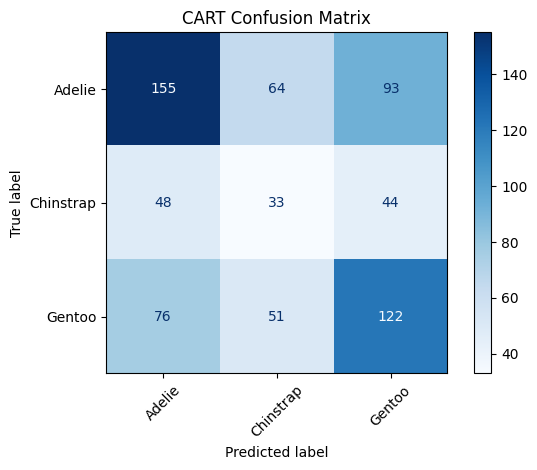

In [ ]:

cart_accuracy = accuracy_score(y_test, y_pred_cart)

print("CART Accuracy:", round(cart_accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_cart))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_cart,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_cart,
    display_labels=le.classes_,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("CART Confusion Matrix")
plt.tight_layout()
plt.show()

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


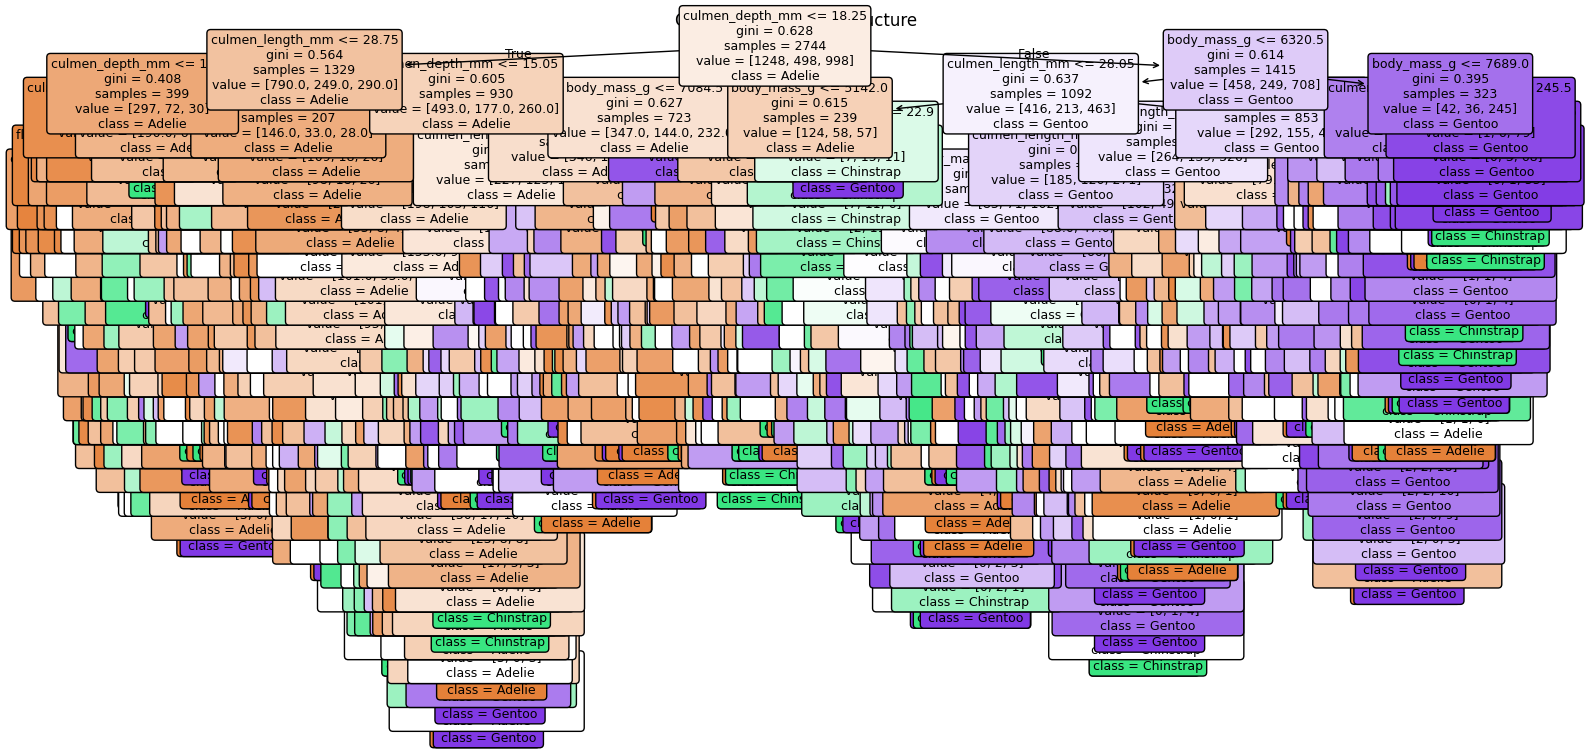

In [ ]:

plt.figure(figsize=(18, 9))

plot_tree(
    cart_model,
    feature_names=features,
    class_names=le.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("CART Decision Tree Structure")
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


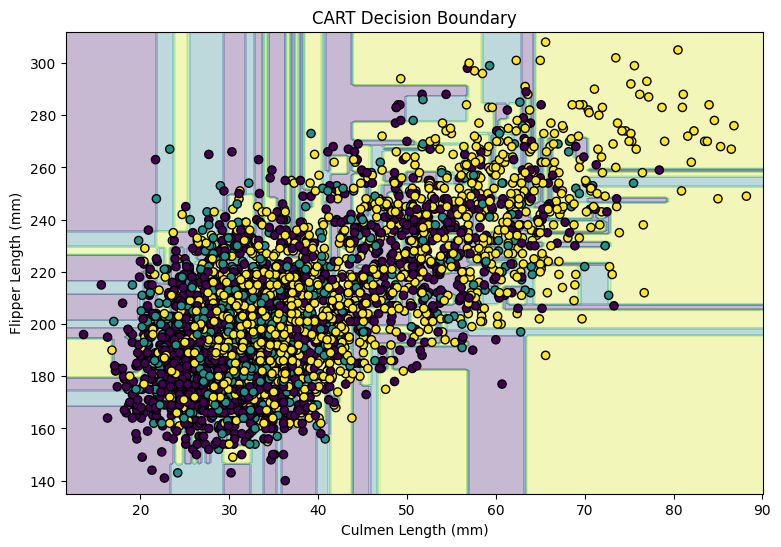

In [ ]:

X2 = data[["culmen_length_mm", "flipper_length_mm"]]
y2 = le.transform(data["species"].astype(str))

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2,
    test_size=0.2,
    random_state=42,
    stratify=y2
)

cart_2d = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)
cart_2d.fit(X2_train, y2_train)

x_min, x_max = X2.iloc[:, 0].min() - 2, X2.iloc[:, 0].max() + 2
y_min, y_max = X2.iloc[:, 1].min() - 5, X2.iloc[:, 1].max() + 5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.5),
    np.arange(y_min, y_max, 1)
)

Z = cart_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
plt.scatter(
    X2.iloc[:, 0], X2.iloc[:, 1],
    c=y2, cmap="viridis",
    edgecolor="black", s=35
)

plt.xlabel("Culmen Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.title("CART Decision Boundary")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


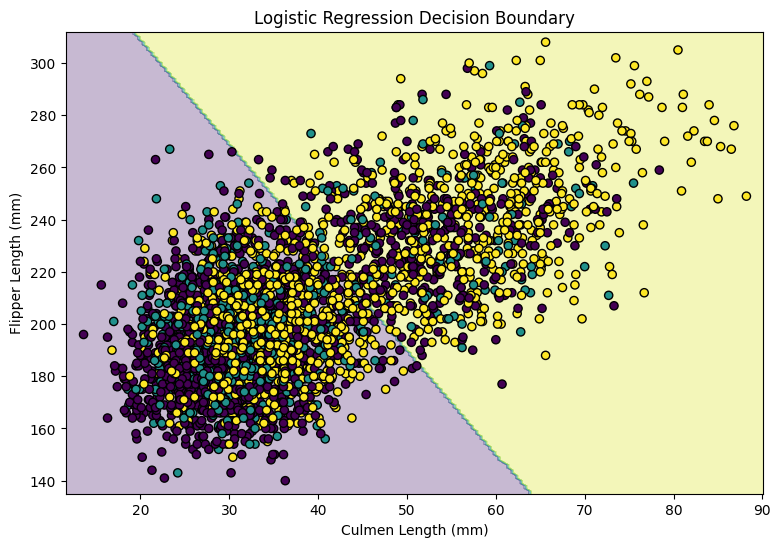

In [ ]:

# Logistic Regression with feature scaling
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

lr_model.fit(X2_train, y2_train)
y_pred_lr = lr_model.predict(X2_test)

Z_lr = lr_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z_lr = Z_lr.reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z_lr, alpha=0.3, cmap="viridis")
plt.scatter(
    X2.iloc[:, 0], X2.iloc[:, 1],
    c=y2, cmap="viridis",
    edgecolor="black", s=35
)

plt.xlabel("Culmen Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.title("Logistic Regression Decision Boundary")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


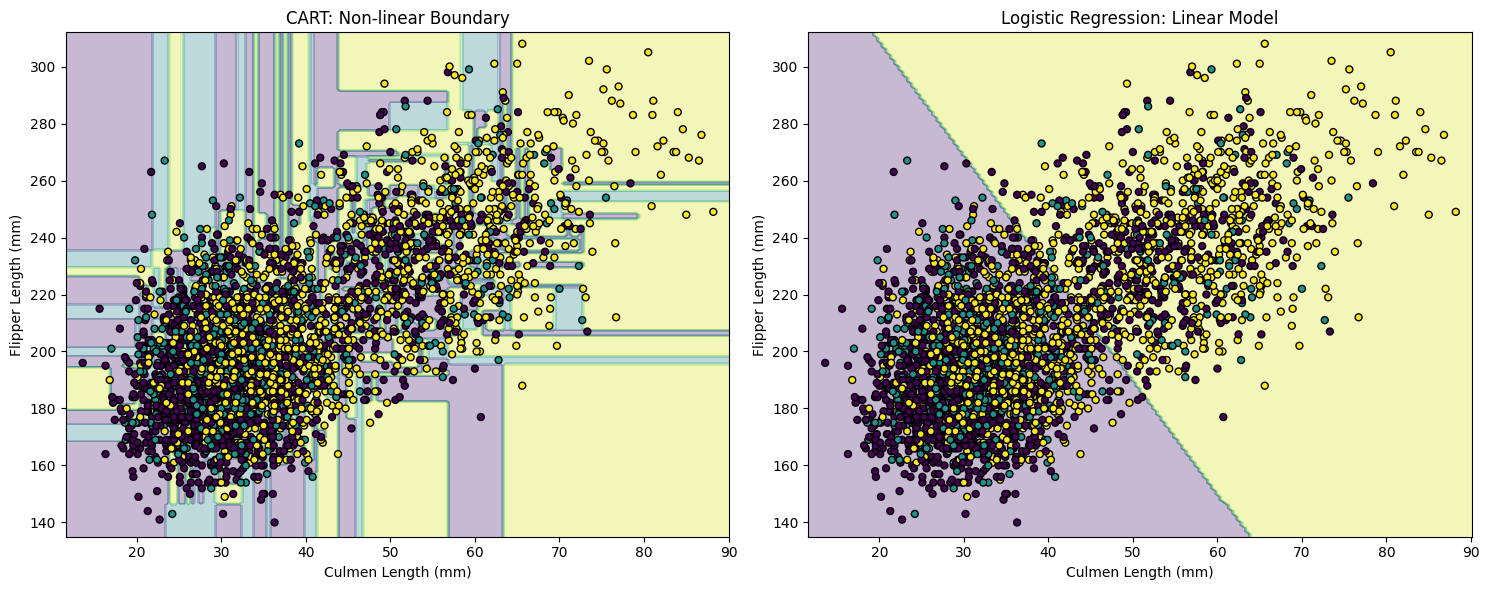

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# CART boundary
axes[0].contourf(xx, yy, cart_2d.predict(
    np.c_[xx.ravel(), yy.ravel()]
).reshape(xx.shape), alpha=0.3, cmap="viridis")

axes[0].scatter(
    X2.iloc[:, 0], X2.iloc[:, 1],
    c=y2, cmap="viridis", edgecolor="black", s=25
)
axes[0].set_title("CART: Non-linear Boundary")
axes[0].set_xlabel("Culmen Length (mm)")
axes[0].set_ylabel("Flipper Length (mm)")

# Logistic Regression boundary
axes[1].contourf(xx, yy, lr_model.predict(
    np.c_[xx.ravel(), yy.ravel()]
).reshape(xx.shape), alpha=0.3, cmap="viridis")

axes[1].scatter(
    X2.iloc[:, 0], X2.iloc[:, 1],
    c=y2, cmap="viridis", edgecolor="black", s=25
)
axes[1].set_title("Logistic Regression: Linear Model")
axes[1].set_xlabel("Culmen Length (mm)")
axes[1].set_ylabel("Flipper Length (mm)")

plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

CART Accuracy: 43.88 %
Logistic Regression Accuracy: 52.62 %

CART Confusion Matrix:
[[156  52 104]
 [ 55  31  39]
 [ 83  52 114]]

Logistic Regression Confusion Matrix:
[[245   0  67]
 [102   0  23]
 [133   0 116]]

CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.53      0.50      0.51       312
   Chinstrap       0.23      0.25      0.24       125
      Gentoo       0.44      0.46      0.45       249

    accuracy                           0.44       686
   macro avg       0.40      0.40      0.40       686
weighted avg       0.44      0.44      0.44       686


Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Adelie       0.51      0.79      0.62       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.47      0.51       249

    accuracy                           0.53       686
   macro avg       0.36      0.42      0.38       686
weig

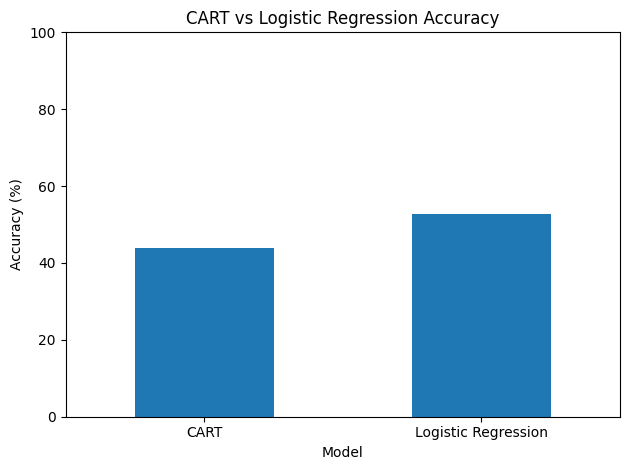

In [ ]:

# Evaluate both models on the same 2-feature test set
y_pred_cart_2d = cart_2d.predict(X2_test)

acc_cart = accuracy_score(y2_test, y_pred_cart_2d)
acc_lr = accuracy_score(y2_test, y_pred_lr)

print("CART Accuracy:", round(acc_cart * 100, 2), "%")
print("Logistic Regression Accuracy:", round(acc_lr * 100, 2), "%")

print("\nCART Confusion Matrix:")
print(confusion_matrix(y2_test, y_pred_cart_2d))

print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(y2_test, y_pred_lr))

print("\nCART Classification Report:")
print(classification_report(
    y2_test, y_pred_cart_2d,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

print("\nLogistic Regression Classification Report:")
print(classification_report(
    y2_test, y_pred_lr,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

comparison = pd.DataFrame({
    "Model": ["CART", "Logistic Regression"],
    "Accuracy (%)": [acc_cart * 100, acc_lr * 100]
})

print("\nPerformance Comparison:")
print(comparison.round(2).to_string(index=False))

comparison.plot(
    x="Model", y="Accuracy (%)",
    kind="bar", legend=False,
    rot=0, ylim=(0, 100)
)
plt.title("CART vs Logistic Regression Accuracy")
plt.ylabel("Accuracy (%)")
plt.tight_layout()
plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.